# Etapa 1 Setup e Carregamento

### 1.1 --> Importar as Bibliotecas e Carregar os 5 Datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings

orders = pd.read_csv(r'C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset brutoolist_orders_dataset.csv',encoding='latin1',sep=',')
review = pd.read_csv(r'C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset brutoolist_order_reviews_dataset.csv',encoding='latin1',sep=',')
costumer = pd.read_csv(r'C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset brutoolist_customers_dataset.csv',encoding='latin1',sep=',')
items = pd.read_csv(r'C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset brutoolist_order_items_dataset.csv',encoding='latin1',sep=',')
sellers = pd.read_csv(r'C:\Users\ACER\Documents\Estudos\FIAP\Fase 1 - Data Analytics\FIAP Tech Challenge Codigos\Dataset brutoolist_sellers_dataset.csv',encoding='latin1',sep=',')

display(orders.columns)
display(review.columns)
display(costumer.columns)
display(items.columns)
display(sellers.columns)

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

Index(['review_id', 'order_id', 'review_score', 'review_comment_title',
       'review_comment_message', 'review_creation_date',
       'review_answer_timestamp'],
      dtype='str')

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'], dtype='str')

### 1.2 --> Enteder cada dataset: .info() & .describe()

In [2]:
print('Dataset Vendas - Info')
display(orders.info())
print('-'*50)
display(review.info())
print('-'*50)
display(costumer.info())
print('-'*50)
display(items.info())
print('-'*50)
display(sellers.info())
print('-'*50)


Dataset Vendas - Info
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


None

--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.9 MB


None

--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


None

--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


None

--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 230.3 KB


None

--------------------------------------------------


Tabela fato vai ser vendas, Identificando colunas para criar tabela fato:

* dataset -> orders: order_id  - customer_id 

* dataset -> review: review_id - order_id

* dataset -> costumer: costumer_id - costumer_unique_id

* dataset -> items: order_id - order_item_id - product_id - seller_id

* dataset -> seller: seller_id

Podemos notar que uma coluna tem a chave de outra, mas nao de todas. Exemplo: O dataset de items e o unico que tem a chave do seller, e se quiser isso em um dataframe so precisamos fazer o cruzamento + resultado com as outras tabelas que se relacionam.

Mas antes de fazer qualquer cruzamento, podemos notar tambem que temos somente o tipo: STR, Float e INT. Mas existe datas nos dataset's, precisamos padronizar antes de fazer a tabela fato


### 1.3 -> Verifcando valores nulos

In [3]:
display(orders.isnull().sum())
print('-'*50)
display(review.isnull().sum())
print('-'*50)
display(costumer.isnull().sum())
print('-'*50)
display(items.isnull().sum())
print('-'*50)
display(sellers.isnull().sum())
print('-'*50)

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

--------------------------------------------------


review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

--------------------------------------------------


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

--------------------------------------------------


order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

--------------------------------------------------


seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

--------------------------------------------------


Existe valores nulos somente nas tabelas  de **Orders** & **Review**. Abaixo esta uma hipotese para os valores serem nulos:

* Coluna order_approved_at: Essa coluna se remete a data de aprovação do pedido, se não foi aprovado logo não tem data. Então esses valores nulos pode ser os pedidos que não foram aprovado de fato.

* Coluna order_delivered_carrier_date: Essa coluna se remete a data de entrega pela transportadora, o pedido pode não ser entregue então não tem data de entrega a transportadora. Isso por X motivos: produto cancelado, danificado, cancelamento...

* Coluna de order_delivered_customer_date: Essa coluna se remete a data de entrega ao cliente, novamente entre no detalhe de conter algumas variavies pra esse acontecimento: cliente indisponivel, cliente não confirmou a entrega, produto não entregue.

**Recomendação: Verificar Dos 2.965 nulos em order_delivered_customer_date, quantos têm status delivered?.**

Olhando pra tabela de review existem algumas colunas com dados nulos:

* Coluna review_comment_title: essa coluna se remete ao titulo da avaliação. Aqui precisamos entender quais campos são obrigatorios para uma avaliação, se titulo não for obrigatorio podemos ter a certeza que esta nulo por esse motivo. Acredito nessa hipotese pois caso contrario as demais colunas tambem estariam nulas.

* Coluna review_comment_message: Essa coluna se remete ao comentario da avaliação. Muitas avalições não tem reamente um comentario, as maiorias das avalição de satisfação existe de fato esse campo de comentario, mas em muitas vezes não sao obrigatorias para preencher. Entao um cliente pode ter adicionado uma nota final mas sem adicionar comentario

**Recomendação: Não excluir pois não muda a analise, mas podemos utilizar em alguma hora.**

### 1.3.2 -> Verificar Status do nulo da coluna de vendas

In [4]:
orders['order_delivered_customer_date'].isnull().groupby(orders['order_status']).sum()

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64

Vendo que somente 8 dos quase 3K de nulos vamos utilizar apenas 8 que estao como entregue. So com esse status podemos validar o calculo de SLA

Mas se exlcuirmos os cancelados podemos perder chance de calculo de churn por cumprimento de SLA

# Etapa 2 Higienização

### Etapa 2.1 -> Converter timestamps object para datatime na tabela de vendas que sera nossa tabela fato

In [5]:
colunas = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in colunas:
    orders[col] = pd.to_datetime(orders[col])
orders[colunas].info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_purchase_timestamp       99441 non-null  datetime64[us]
 1   order_approved_at              99281 non-null  datetime64[us]
 2   order_delivered_carrier_date   97658 non-null  datetime64[us]
 3   order_delivered_customer_date  96476 non-null  datetime64[us]
 4   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5)
memory usage: 3.8 MB


### Etapa 2.2 -> Verificando duplicidade das chaves unicas. 

##### (O order_id é o identificador único de um pedido. Se ele aparecer mais de uma vez no orders, significa que o mesmo pedido está registrado duas vezes — o que seria um erro de dados.)

In [6]:
print(f'1) DUPLICIDADE VENDAS')
display(orders['order_id'].duplicated().sum())
print('>'*25)

print('2) DUPLICIDADE DE REVIEW')
display(review['review_id'].duplicated().sum())
print('>'*25)

print('3) DUPLICIDADE COSTUMER')
display(costumer['customer_unique_id'].duplicated().sum())
print('>'*25)

print('4) DUPLICIDADE ITEMS')
display(items['order_item_id'].duplicated().sum())
print('>'*25)

print('5) DUPLICIDADE SELLER')
display(sellers['seller_id'].duplicated().sum())
print('>'*25)

1) DUPLICIDADE VENDAS


np.int64(0)

>>>>>>>>>>>>>>>>>>>>>>>>>
2) DUPLICIDADE DE REVIEW


np.int64(814)

>>>>>>>>>>>>>>>>>>>>>>>>>
3) DUPLICIDADE COSTUMER


np.int64(3345)

>>>>>>>>>>>>>>>>>>>>>>>>>
4) DUPLICIDADE ITEMS


np.int64(112629)

>>>>>>>>>>>>>>>>>>>>>>>>>
5) DUPLICIDADE SELLER


np.int64(0)

>>>>>>>>>>>>>>>>>>>>>>>>>


Podemos ver que existe valores de cahve unicas duplicados nas tabelas de: REVIEW, COSTUMER, ITEMS

* customer_unique_id → não mexe, é comportamento esperado
* order_item_id → não mexe, é a estrutura natural da tabela
* review_id → precisa investigar

#### 2.3.2 Verificando nulos da tabela de reviews

In [7]:
revw_duplicados = review[review['review_id'].duplicated()]
revw_duplicados.groupby('review_id')['order_id'].count().reset_index().sort_values('order_id',ascending=False)

,review_id,order_id
196,4219a80ab469e3fc9901437b73da3f75,2
383,7b606b0d57b078384f0b58eac1d41d78,2
35,0c76e7a547a531e7bf9f0b99cba071c1,2
323,69a1068c3128a14994e3e422e4539e04,2
137,308316408775d1600dad81bd3184556d,2
...,...,...
784,fde2e6abaf5bb64f7407a44741c24dec,1
785,fde5986d35c89aa1b6ce4149de82a0d3,1
786,fe5c833752953fed3209646f1f63b53c,1
787,ff2fc9e68f8aabfbe18d710b83aabd30,1


Identificamos 814 review_id duplicados associados a order_id diferentes.
Não é possível determinar qual o pedido correto nesse momento.
Decisão: tratar após o join na Fase 3, quando teremos o contexto completo do pedido.
Após filtrar apenas os pedidos delivered, verificaremos quantos duplicados persistem e aí tomaremos a decisão final.

#### Etapa 2.4 -> Separar grupo problema: delivered sem data de entrega

In [8]:
# Separando os dados que estao como entregue mas com data de entrega nulo em um dataset a parte
delivered_semData = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].isna())
]

#removendo os dados que estao como entregue mas com data de entrega nulo
id_orders_nulos = delivered_semData['order_id'].unique().tolist()
orders = orders[~orders['order_id'].isin(id_orders_nulos)]

print(f'dataset "delivered_semData" (linhas,colunas): {delivered_semData.shape}')
print(f'dataset "orders" (linhas,colunas): {orders.shape}')

dataset "delivered_semData" (linhas,colunas): (8, 8)
dataset "orders" (linhas,colunas): (99433, 8)


### Etapa 2.5 Padronizar colunas

Como vamos fazer join agora, vamos preparar o dataset pra isso, padronizando o tipo para que nao ocorra nenhum erro, como cruzar uma coluna int com str


Vamos fazer o cruzamento com essas colunas
* dataset -> orders: order_id  - customer_id 

* dataset -> review: review_id - order_id

* dataset -> costumer: costumer_id - costumer_unique_id

* dataset -> items: order_id - order_item_id - product_id - seller_id

* dataset -> seller: seller_id

In [9]:
def padronizacao(coluna):
    return coluna.astype(str)

orders[['order_id','customer_id']] = padronizacao(orders[['order_id','customer_id']])
review[['review_id','order_id']] = padronizacao(review[['review_id','order_id']])
costumer[['customer_id','customer_unique_id']] = padronizacao(costumer[['customer_id','customer_unique_id']])
items[['order_id','order_item_id','product_id','seller_id']] = padronizacao(items[['order_id','order_item_id','product_id','seller_id']])
sellers['seller_id'] = padronizacao(sellers['seller_id'])

print('orders')
print(orders[['order_id','customer_id']].dtypes)

print('\nreview')
print(review[['review_id','order_id']].dtypes)

print('\ncostumer')
print(costumer[['customer_id','customer_unique_id']].dtypes)

print('\nitems')
print(items[['order_id','order_item_id','product_id','seller_id']].dtypes)

print('\nsellers')
print(sellers[['seller_id']].dtypes)

orders
order_id       str
customer_id    str
dtype: object

review
review_id    str
order_id     str
dtype: object

costumer
customer_id           str
customer_unique_id    str
dtype: object

items
order_id         str
order_item_id    str
product_id       str
seller_id        str
dtype: object

sellers
seller_id    str
dtype: object


Validado, todas colunas no mesmo tipo

# Etapa 3 Costrução tabela fato

Vamos utilizar essas colunas para cruzamento:
* dataset -> orders: order_id  - costomer_id 

* dataset -> review: review_id - order_id

* dataset -> costumer: costumer_id - costumer_unique_id

* dataset -> items: order_id - order_item_id - product_id - seller_id

* dataset -> seller: seller_id

Vamos criar nossa tabela fato mas antes vamos definir a order do cruzamento:

- Order + costumer
- Resultado + review 
- Resultado + items
- Resultado + seller



Vamos utilizar essas colunas para cruzamento:
* dataset -> orders: order_id  - costomer_id 

* dataset -> review: review_id - order_id

* dataset -> costumer: costumer_id - costumer_unique_id

* dataset -> items: order_id - order_item_id - product_id - seller_id

* dataset -> seller: seller_id

Vamos criar nossa tabela fato mas antes vamos definir a order do cruzamento:

- Order + costumer
- Resultado + review 
- Resultado + items
- Resultado + seller



Vamos utilizar essas colunas para cruzamento:
* dataset -> orders: order_id  - costomer_id 

* dataset -> review: review_id - order_id

* dataset -> costumer: costumer_id - costumer_unique_id

* dataset -> items: order_id - order_item_id - product_id - seller_id

* dataset -> seller: seller_id

Vamos criar nossa tabela fato mas antes vamos definir a order do cruzamento:

- Order + costumer
- Resultado + review 
- Resultado + items
- Resultado + seller



#### Etapa 3.1 Agregando valores items

Vamos agregar o items assim:

- seller_id → pegar o primeiro de cada pedido
- price → somar tudo — valor total do pedido
- freight_value → somar tudo — frete total do pedido

O dataset items tem os itens de cada pedido. Um pedido pode ter vários itens, logo várias linhas. Você quer juntar isso com orders que tem 1 linha por pedido.
Para não bagunçar o join, você precisa transformar o items em 1 linha por pedido também — somando o preço, somando o frete, e pegando o seller do primeiro item.

In [10]:
items_agrupado = items.groupby('order_id', as_index=False).agg(
    seller_id=('seller_id', 'first'),
    total_price=('price', 'sum'),
    total_freight_value=('freight_value', 'sum')
)

items_agrupado

,order_id,seller_id,total_price,total_freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,199.90,18.14
...,...,...,...,...
98661,fffc94f6ce00a00581880bf54a75a037,b8bc237ba3788b23da09c0f1f3a3288c,299.99,43.41
98662,fffcd46ef2263f404302a634eb57f7eb,f3c38ab652836d21de61fb8314b69182,350.00,36.53
98663,fffce4705a9662cd70adb13d4a31832d,c3cfdc648177fdbbbb35635a37472c53,99.90,16.95
98664,fffe18544ffabc95dfada21779c9644f,2b3e4a2a3ea8e01938cabda2a3e5cc79,55.99,8.72


#### 3.1.2 -> Agrupando Reviews 

In [11]:
review.columns

review_agrupado = review.groupby('order_id', as_index=False).agg(
    review_id=('review_id', 'first'),
    review_score=('review_score', 'first')
)

review_agrupado

,order_id,review_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,97ca439bc427b48bc1cd7177abe71365,5
1,00018f77f2f0320c557190d7a144bdd3,7b07bacd811c4117b742569b04ce3580,4
2,000229ec398224ef6ca0657da4fc703e,0c5b33dea94867d1ac402749e5438e8b,5
3,00024acbcdf0a6daa1e931b038114c75,f4028d019cb58564807486a6aaf33817,4
4,00042b26cf59d7ce69dfabb4e55b4fd9,940144190dcba6351888cafa43f3a3a5,5
...,...,...,...
98668,fffc94f6ce00a00581880bf54a75a037,9185f849f32d82e216a4e025e0c50f5c,5
98669,fffcd46ef2263f404302a634eb57f7eb,be803f6a93d64719fd685c1cc610918a,5
98670,fffce4705a9662cd70adb13d4a31832d,dbdd81cd59a1a9f94a10a990b4d48dce,5
98671,fffe18544ffabc95dfada21779c9644f,fba117c9ac40d41ca7be54741f471303,5


#### 3.2 -> Fazendo o cruzamento

Vamos utilizar essas colunas para cruzamento:
* dataset -> orders: order_id  - costomer_id 

* dataset -> review: review_id - order_id

* dataset -> costumer: costumer_id - costumer_unique_id

* dataset -> items: order_id - order_item_id - product_id - seller_id

* dataset -> seller: seller_id

Vamos criar nossa tabela fato mas antes vamos definir a order do cruzamento:

- Order + costumer
- Resultado + review_agrupados 
- Resultado + items_agrupados
- Resultado + seller



In [12]:
sellers.columns

Index(['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state'], dtype='str')

In [13]:
fato = orders.merge(
    costumer[['customer_city','customer_state','customer_unique_id']],
    how='left',
    left_on='customer_id',
    right_on=costumer['customer_id']
)

fato = fato.merge(
    review_agrupado['review_score'],
    how='left',
    left_on='order_id',
    right_on=review_agrupado['order_id']
)

fato = fato.merge(
    items_agrupado[['seller_id', 'total_price', 'total_freight_value']],
    how='left',
    left_on='order_id',
    right_on=items_agrupado['order_id']
)

fato = fato.merge(
    sellers[['seller_city', 'seller_state']],
    how='left',
    left_on='seller_id',
    right_on=sellers['seller_id']
)

fato.shape

(99433, 17)

#### 3.3 Filtrando apenas os que estao com status 'delivered'

In [14]:
fato = fato[fato['order_status'] == 'delivered'].copy()
fato.shape

(96470, 17)

# Etapa 4 Engenharia de Features

#### Etapa 4.1 -> criar tempo entre compra e aprovação

In [15]:
fato['t_aprovacao_hrs'] = (
    (fato['order_approved_at'] - fato['order_purchase_timestamp'])
    .dt.total_seconds() / 3600
)

#### Etapa 4.2 -> Criar tempo entre aprovação e postagem na transportadora

In [16]:
fato['t_postagem_hrs'] = (
    (fato['order_delivered_carrier_date'] - fato['order_approved_at'] )
    .dt.total_seconds() / 3600)

#### Etapa 4.3 -> Criar tempo entre postagem e entrega ao cliente

In [17]:
fato['t_transito_hrs'] = (
    (fato['order_delivered_customer_date'] - fato['order_delivered_carrier_date'])
    .dt.total_seconds() / 3600
)

#### Etapa 4.4 -> Criar tempo total entre compra e entrega

In [18]:
fato['t_total_dias'] = (
    (fato['order_delivered_customer_date'] - fato['order_purchase_timestamp'])
    .dt.total_seconds() / 86400
).round(2)
fato

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_city,customer_state,...,review_score,seller_id,total_price,total_freight_value,seller_city,seller_state,t_aprovacao_hrs,t_postagem_hrs,t_transito_hrs,t_total_dias
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,sao paulo,SP,...,4.0,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,maua,SP,0.178333,56.795833,145.503611,8.44
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,barreiras,BA,...,4.0,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,belo horizonte,SP,30.713889,11.109167,288.945833,13.78
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,vianopolis,GO,...,5.0,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,guariba,SP,0.276111,4.910278,220.274722,9.39
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,sao goncalo do amarante,RN,...,5.0,66922902710d126a0e7d26b0e3805106,45.00,27.20,belo horizonte,MG,0.298056,89.900000,226.811944,13.21
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,santo andre,SP,...,5.0,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,mogi das cruzes,SP,1.030556,21.434722,46.507778,2.87
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99428,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,sao jose dos campos,SP,...,5.0,e24fc9fcd865784fb25705606fe3dfe7,72.00,13.08,braganca paulista,SP,0.000000,25.399444,171.832778,8.22
99429,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,praia grande,SP,...,4.0,1f9ab4708f3056ede07124aad39a2554,174.90,20.10,tupa,SP,0.194167,34.201389,498.253889,22.19
99430,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,nova vicosa,BA,...,5.0,d50d79cb34e38265a8649c383dcffd48,205.99,65.02,sao paulo,SP,0.292500,29.802778,566.530833,24.86
99431,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,japuiba,RJ,...,2.0,a1043bafd471dff536d0c462352beb48,359.98,81.18,ilicinea,MG,0.131667,89.978333,319.964167,17.09


#### Etapa 4.5 -> Criar diferença entre entrega real e entrega estimada

In [19]:
fato['sla_diff_dias'] = (
    ( fato['order_delivered_customer_date'] - fato['order_estimated_delivery_date'])
       .dt.total_seconds() / 86400
).round(2)
fato

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_city,customer_state,...,seller_id,total_price,total_freight_value,seller_city,seller_state,t_aprovacao_hrs,t_postagem_hrs,t_transito_hrs,t_total_dias,sla_diff_dias
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,sao paulo,SP,...,3504c0cb71d7fa48d967e0e4c94d59d9,29.99,8.72,maua,SP,0.178333,56.795833,145.503611,8.44,-7.11
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,barreiras,BA,...,289cdb325fb7e7f891c38608bf9e0962,118.70,22.76,belo horizonte,SP,30.713889,11.109167,288.945833,13.78,-5.36
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,vianopolis,GO,...,4869f7a5dfa277a7dca6462dcf3b52b2,159.90,19.22,guariba,SP,0.276111,4.910278,220.274722,9.39,-17.25
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,sao goncalo do amarante,RN,...,66922902710d126a0e7d26b0e3805106,45.00,27.20,belo horizonte,MG,0.298056,89.900000,226.811944,13.21,-12.98
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,santo andre,SP,...,2c9e548be18521d1c43cde1c582c6de8,19.90,8.72,mogi das cruzes,SP,1.030556,21.434722,46.507778,2.87,-9.24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99428,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,sao jose dos campos,SP,...,e24fc9fcd865784fb25705606fe3dfe7,72.00,13.08,braganca paulista,SP,0.000000,25.399444,171.832778,8.22,-10.37
99429,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,praia grande,SP,...,1f9ab4708f3056ede07124aad39a2554,174.90,20.10,tupa,SP,0.194167,34.201389,498.253889,22.19,-1.27
99430,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,nova vicosa,BA,...,d50d79cb34e38265a8649c383dcffd48,205.99,65.02,sao paulo,SP,0.292500,29.802778,566.530833,24.86,-5.52
99431,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,japuiba,RJ,...,a1043bafd471dff536d0c462352beb48,359.98,81.18,ilicinea,MG,0.131667,89.978333,319.964167,17.09,-20.02


#### Etapa 4.6 -> Criar flag atrasado → 0 se no prazo, 1 se atrasou

In [20]:
fato['atraso'] = (
    fato['order_delivered_customer_date'] > fato['order_estimated_delivery_date']
).astype(int)
fato['atraso'].value_counts()

atraso
0    88644
1     7826
Name: count, dtype: int64

#### 4.7 Visao rapida, verificar quantos pedidos atrasam

In [21]:
fato['atraso'].value_counts()

atraso
0    88644
1     7826
Name: count, dtype: int64

In [22]:
fato

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_city,customer_state,...,total_price,total_freight_value,seller_city,seller_state,t_aprovacao_hrs,t_postagem_hrs,t_transito_hrs,t_total_dias,sla_diff_dias,atraso
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,sao paulo,SP,...,29.99,8.72,maua,SP,0.178333,56.795833,145.503611,8.44,-7.11,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,barreiras,BA,...,118.70,22.76,belo horizonte,SP,30.713889,11.109167,288.945833,13.78,-5.36,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,vianopolis,GO,...,159.90,19.22,guariba,SP,0.276111,4.910278,220.274722,9.39,-17.25,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,sao goncalo do amarante,RN,...,45.00,27.20,belo horizonte,MG,0.298056,89.900000,226.811944,13.21,-12.98,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,santo andre,SP,...,19.90,8.72,mogi das cruzes,SP,1.030556,21.434722,46.507778,2.87,-9.24,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99428,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,sao jose dos campos,SP,...,72.00,13.08,braganca paulista,SP,0.000000,25.399444,171.832778,8.22,-10.37,0
99429,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,praia grande,SP,...,174.90,20.10,tupa,SP,0.194167,34.201389,498.253889,22.19,-1.27,0
99430,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,nova vicosa,BA,...,205.99,65.02,sao paulo,SP,0.292500,29.802778,566.530833,24.86,-5.52,0
99431,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,japuiba,RJ,...,359.98,81.18,ilicinea,MG,0.131667,89.978333,319.964167,17.09,-20.02,0


- 88.644 pedidos entregues no prazo — 91,9%
- 7.826 pedidos atrasados — 8,1%

#### Etapa 4.7 -> Se existem valores negativos nessas colunas: aprovacao_hrs, t_postagem_hrs, t_transito_hrs e t_total_dias

verificar é possível um pedido ser aprovado antes de ser comprado? Ou ser postado antes de ser aprovado?

In [23]:
display(fato['t_aprovacao_hrs'].describe())
print('-'*50)
display(fato['t_postagem_hrs'].describe())
print('-'*50)
display(fato['t_transito_hrs'].describe())
display(fato['t_total_dias'].describe())

count    96456.000000
mean        10.277598
std         20.536068
min          0.000000
25%          0.215278
50%          0.343333
75%         14.517014
max        741.443611
Name: t_aprovacao_hrs, dtype: float64

--------------------------------------------------


count    96455.000000
mean        67.177166
std         84.892152
min      -4109.256111
25%         20.980972
50%         43.579444
75%         85.798333
max       3018.301667
Name: t_postagem_hrs, dtype: float64

--------------------------------------------------


count    96469.000000
mean       223.927129
std        210.238168
min       -386.308056
25%         98.401111
50%        170.394444
75%        288.687500
max       4924.583333
Name: t_transito_hrs, dtype: float64

count    96470.000000
mean        12.558201
std          9.546155
min          0.530000
25%          6.770000
50%         10.220000
75%         15.720000
max        209.630000
Name: t_total_dias, dtype: float64

- t_postagem_hrs com mínimo de -4109 horas — isso é fisicamente impossível. A postagem não pode acontecer antes da aprovação.
- t_transito_hrs com mínimo de -386 horas — mesma coisa, entrega não pode acontecer antes da postagem.

 sistema registrou a aprovação depois da postagem. Isso é um erro de registro de dado — provavelmente falha operacional no sistema da Olist.

In [24]:
display((fato['t_postagem_hrs'] < 0).sum())
display((fato['t_transito_hrs'] < 0).sum())

np.int64(1350)

np.int64(23)

1.350 registros com postagem negativa e 23 com trânsito negativo.

Vamos tirar esses dados da tabela fato e armazenar em outra tabela, fazendo assim a governança de dados

#### 4.8 Tratativa desses registro com falha

In [25]:
registro_falha_negativos = fato[(fato['t_postagem_hrs'] < 0) | (fato['t_transito_hrs'] < 0)]
fato = fato[~((fato['t_postagem_hrs'] < 0) | (fato['t_transito_hrs'] < 0))]



In [26]:
display(fato.shape)
display(registro_falha_negativos.shape)

(95097, 23)

(1373, 23)

# Etapa 5 Analises

### Etapa 5.1-> Lead time: qual etapa esta o gargalo

In [27]:
print(f'Tempo medio APROVAÇÃO: {fato['t_aprovacao_hrs'].mean().round(2)} hrs \nTempo medio POSTAGEM: {fato['t_postagem_hrs'].mean().round(2)} hrs \nTempo medio TRANSITO: {fato['t_transito_hrs'].mean().round(2)} hrs')

Tempo medio APROVAÇÃO: 9.65 hrs 
Tempo medio POSTAGEM: 68.44 hrs 
Tempo medio TRANSITO: 224.74 hrs


- Aprovação: 9,65 hrs → ~0,4 dias
- Postagem: 68,44 hrs → ~2,8 dias
- Trânsito: 224,74 hrs → ~9,4 dias

Pegando somente a media podemos ver que o tempo maior e quando esta em transito e o menor e da aprovação. 

Olhando esse tempo medio de transito podemos ter uma hipotese que esse tempo medio deve ser por lugares mais longe do local de envio.

5.1.2 -> Verificando outras medidas

In [28]:
print(f'Medidas APROVAÇÃO: {fato['t_aprovacao_hrs'].describe().round(2)} hrs \n{'-'*40}\nMedidas POSTAGEM: {fato['t_postagem_hrs'].describe().round(2)} hrs \n{'-'*20}\nMedidas TRANSITO: {fato['t_transito_hrs'].describe().round(2)} hrs')

Medidas APROVAÇÃO: count    95083.00
mean         9.65
std         19.12
min          0.00
25%          0.21
50%          0.34
75%         13.54
max        741.44
Name: t_aprovacao_hrs, dtype: float64 hrs 
----------------------------------------
Medidas POSTAGEM: count    95082.00
mean        68.44
std         83.59
min          0.00
25%         21.61
50%         44.37
75%         86.78
max       3018.30
Name: t_postagem_hrs, dtype: float64 hrs 
--------------------
Medidas TRANSITO: count    95096.00
mean       224.74
std        210.45
min          0.00
25%         98.68
50%        170.65
75%        289.38
max       4924.58
Name: t_transito_hrs, dtype: float64 hrs


Dessa forma podemos ter uma visao mais clara sobre as medidas das colunas de lead time:

- **Coluna Aprovação:** temos uma media de 9.65 mas uma mediana de 0.34. Tambem possui um desvio padrao de  19.12. Com isso podemos falar que os dados estao mutio heterogeneos e distribuidos. Entao podemos ter valordes de 0.21 e valores chegando ate 741 horas

- **Coluna Postagem:** Temos uma media de 68.44 e uma mediana de 44, nova,emte a ,media ficando longe da mediana, dessa vez com 66% do valor da mediana

- **Coluna de Transito:** Temos uma media de 224,74 e uma mediana de 170.65, novamente media maior que a mediana, podemos falar que os dados nao estao equilibrados, podemos comprovar isso com o desvio padrao de 

Resumo: Os dados estao heterogenos com uma grande dispersao entre um valor e outro. Podemos confirmar que existe outliers sim!

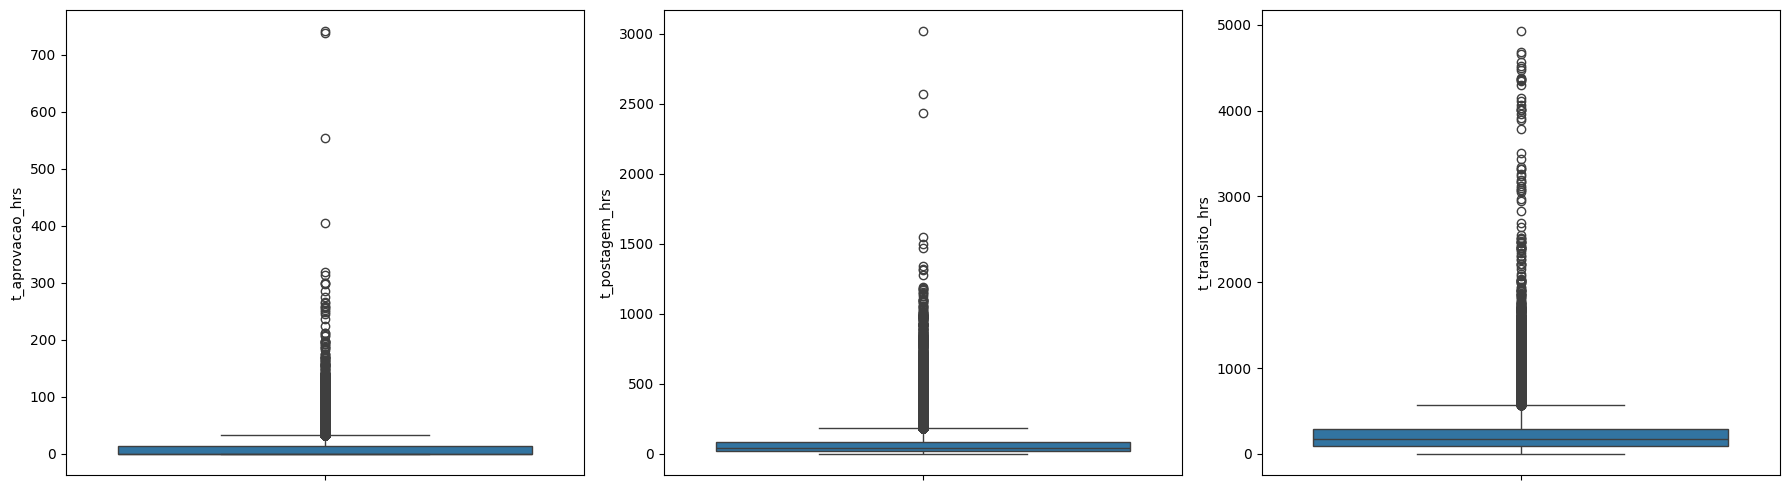

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=fato, y='t_aprovacao_hrs', ax=axes[0])
sns.boxplot(data=fato, y='t_postagem_hrs',ax=axes[1])
sns.boxplot(data=fato,y='t_transito_hrs',ax=axes[2])

plt.tight_layout()
plt.show()

Existem muitos outliers em todas as colunas. em uma tratativa como essa eu recomendaria excluir os outliers pois assim nao vamos achar um padrao para analise , mas sim tendo a visao geral e esses casos manipulando o resultado

#### Etapa 5.1.3 -> usar IQR analisar a dispersão dos dados sem deixar valores extremos bagunçarem tudo

Selecionando somente dados sem outlier, mas nao vamos excluir da nossa base

In [30]:
Q1_ap = fato['t_aprovacao_hrs'].quantile(0.25)
Q3_ap = fato['t_aprovacao_hrs'].quantile(0.75)
IQR_ap = Q3_ap - Q1_ap
LI_ap = Q1_ap - 1.5 * IQR_ap
LS_ap = Q3_ap + 1.5 * IQR_ap

Q1_po = fato['t_postagem_hrs'].quantile(0.25)
Q3_po = fato['t_postagem_hrs'].quantile(0.75)
IQR_po = Q3_po - Q1_po
LI_po = Q1_po - 1.5 * IQR_po
LS_po = Q3_po + 1.5 * IQR_po

Q1_tr = fato['t_transito_hrs'].quantile(0.25)
Q3_tr = fato['t_transito_hrs'].quantile(0.75)
IQR_tr = Q3_tr - Q1_tr
LI_tr = Q1_tr - 1.5 * IQR_tr
LS_tr = Q3_tr + 1.5 * IQR_tr

fato_sem_outliers = fato[
    (fato['t_aprovacao_hrs'] > LI_ap) & (fato['t_aprovacao_hrs'] < LS_ap) &
    (fato['t_postagem_hrs'] > LI_po) & (fato['t_postagem_hrs'] < LS_po) &
    (fato['t_transito_hrs'] > LI_tr) & (fato['t_transito_hrs'] < LS_tr)
]

display(fato_sem_outliers.shape)
fato_sem_outliers

(76699, 23)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_city,customer_state,...,total_price,total_freight_value,seller_city,seller_state,t_aprovacao_hrs,t_postagem_hrs,t_transito_hrs,t_total_dias,sla_diff_dias,atraso
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,sao paulo,SP,...,29.99,8.72,maua,SP,0.178333,56.795833,145.503611,8.44,-7.11,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,barreiras,BA,...,118.70,22.76,belo horizonte,SP,30.713889,11.109167,288.945833,13.78,-5.36,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,vianopolis,GO,...,159.90,19.22,guariba,SP,0.276111,4.910278,220.274722,9.39,-17.25,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,sao goncalo do amarante,RN,...,45.00,27.20,belo horizonte,MG,0.298056,89.900000,226.811944,13.21,-12.98,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,santo andre,SP,...,19.90,8.72,mogi das cruzes,SP,1.030556,21.434722,46.507778,2.87,-9.24,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99428,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,sao jose dos campos,SP,...,72.00,13.08,braganca paulista,SP,0.000000,25.399444,171.832778,8.22,-10.37,0
99429,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,praia grande,SP,...,174.90,20.10,tupa,SP,0.194167,34.201389,498.253889,22.19,-1.27,0
99430,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,nova vicosa,BA,...,205.99,65.02,sao paulo,SP,0.292500,29.802778,566.530833,24.86,-5.52,0
99431,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,japuiba,RJ,...,359.98,81.18,ilicinea,MG,0.131667,89.978333,319.964167,17.09,-20.02,0


#### 5.1.3 -> Visualização em boxplot

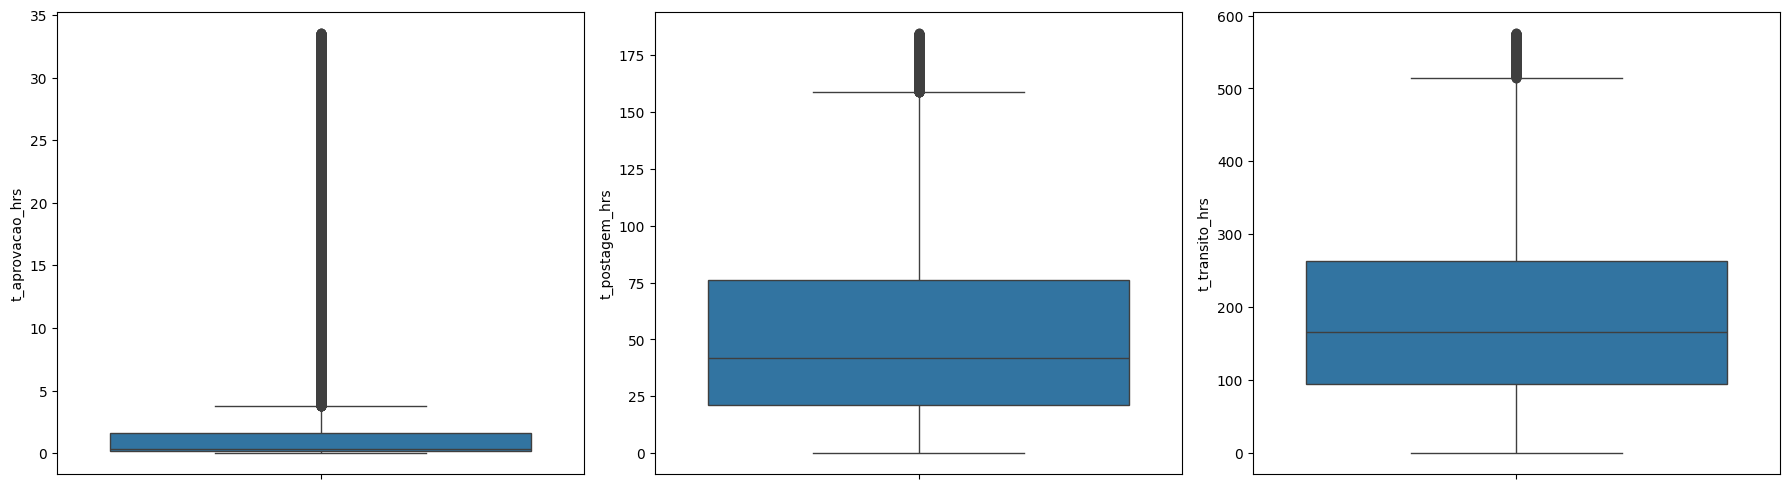

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=fato_sem_outliers, y='t_aprovacao_hrs', ax=axes[0])
sns.boxplot(data=fato_sem_outliers, y='t_postagem_hrs',ax=axes[1])
sns.boxplot(data=fato_sem_outliers,y='t_transito_hrs',ax=axes[2])

plt.tight_layout()
plt.show()

t_aprovacao_hrs tem forte concentração em valores baixos com muitos outliers, enquanto t_postagem_hrs e principalmente t_transito_hrs apresentam maior dispersão e tempos centrais bem mais altos, indicando que o maior gargalo está no trânsito.

#### Etapa 5.2 -> Criar coluna ano mes

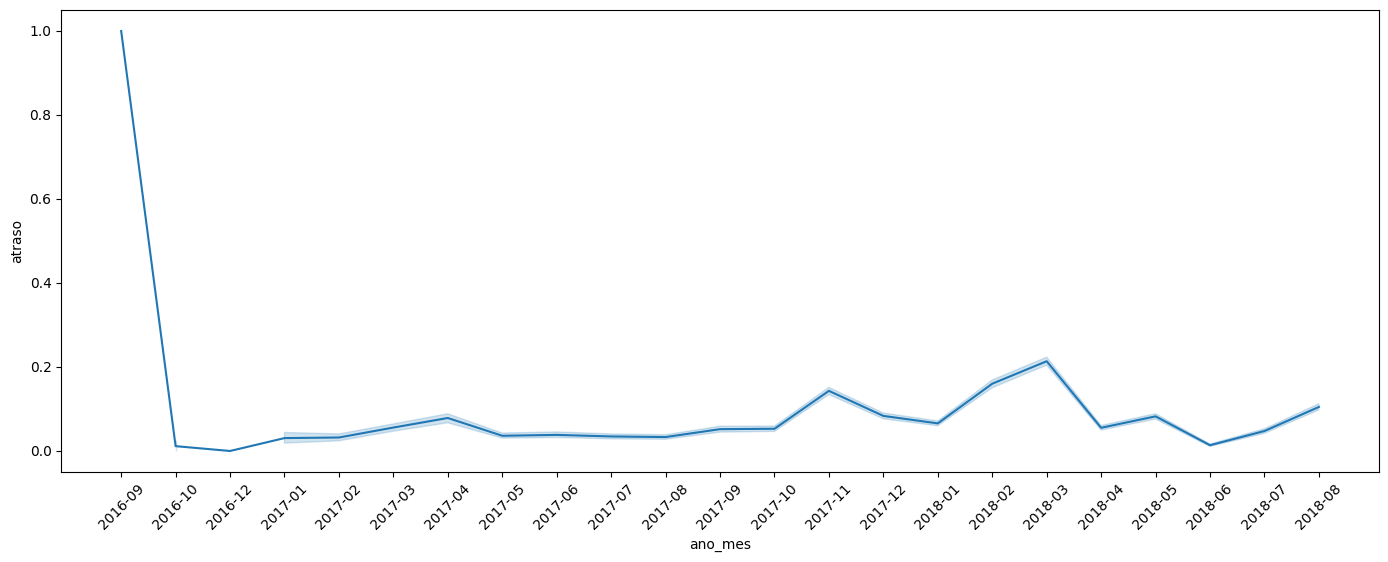

In [32]:
fato['ano_mes'] = fato['order_purchase_timestamp'].dt.strftime('%Y-%m')
fato_sorted = fato.sort_values('order_purchase_timestamp')
fato_sorted['ano_mes'] = fato_sorted['order_purchase_timestamp'].dt.strftime('%Y-%m')

plt.figure(figsize=(17,6))
sns.lineplot(data=fato_sorted, x='ano_mes', y='atraso')
plt.xticks(rotation=45)
plt.show()

O gráfico mostra que setembro de 2016 é um outlier claro com taxa de atraso de 100% — quase certamente por volume de pedidos ínfimo naquele mês de estreia da plataforma — e a partir de outubro de 2016 a taxa se estabiliza em torno de 5% com pequenas oscilações, tendo um pico moderado em março de 2018 (~21%) que merece investigação mas não chega a representar uma ruptura estrutural na operação.

#### Analisando pico de marco

- Volume → chegaram muito mais pedidos que o normal naquele mês, sobrecarregando a operação
- Região → algum estado específico puxou o atraso pra cima naquele período

In [33]:
fato.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_city', 'customer_state', 'customer_unique_id', 'review_score',
       'seller_id', 'total_price', 'total_freight_value', 'seller_city',
       'seller_state', 't_aprovacao_hrs', 't_postagem_hrs', 't_transito_hrs',
       't_total_dias', 'sla_diff_dias', 'atraso', 'ano_mes'],
      dtype='str')

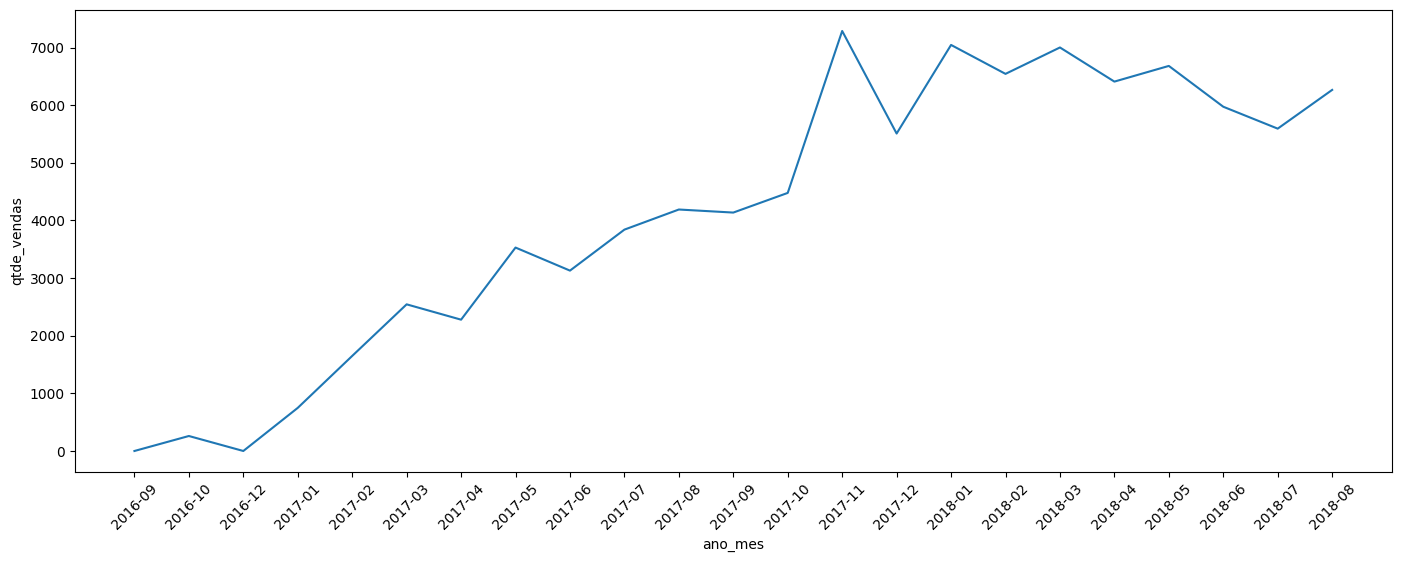

In [34]:
qtde_vendas = fato.groupby('ano_mes').agg(
    qtde_vendas=('order_id', 'count')
).reset_index()

qtde_vendas['ano_mes'] = qtde_vendas['ano_mes'].astype(str)

plt.figure(figsize=(17,6))
sns.lineplot(data=qtde_vendas, x='ano_mes', y='qtde_vendas')
plt.xticks(rotation=45)
plt.show()

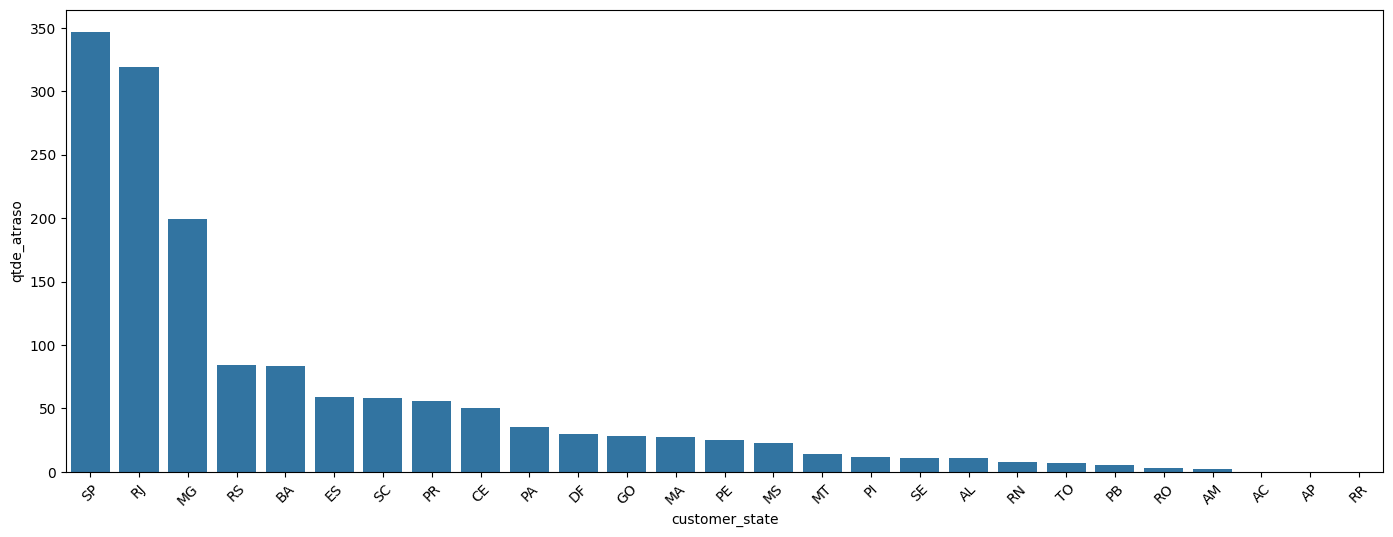

In [35]:
uf_atraso = fato[fato['ano_mes'] == '2018-03'].groupby('customer_state').agg(
    qtde_atraso=('atraso', 'sum')
).reset_index().sort_values('qtde_atraso', ascending=False)

plt.figure(figsize=(17,6))
sns.barplot(data=uf_atraso, x='customer_state', y='qtde_atraso')
plt.xticks(rotation=45)
plt.show()

Olhando os dois gráficos em conjunto, a conclusão é direta: o pico de atraso em março de 2018 é concentrado em SP (~345) e RJ (~320), que juntos respondem por mais da metade de todos os atrasos do mês, seguidos de MG com ~200. Isso não é um problema operacional distribuído — é um problema geograficamente concentrado no eixo Sudeste, o que faz sentido dado que esse eixo também concentra o maior volume de vendas, conforme o primeiro gráfico mostra a partir de novembro de 2017. Em outras palavras, março de 2018 não foi um mês em que a operação piorou para todo o Brasil — foi um mês em que os grandes estados não aguentaram o volume que vinham acumulando desde o Black Friday de 2017.

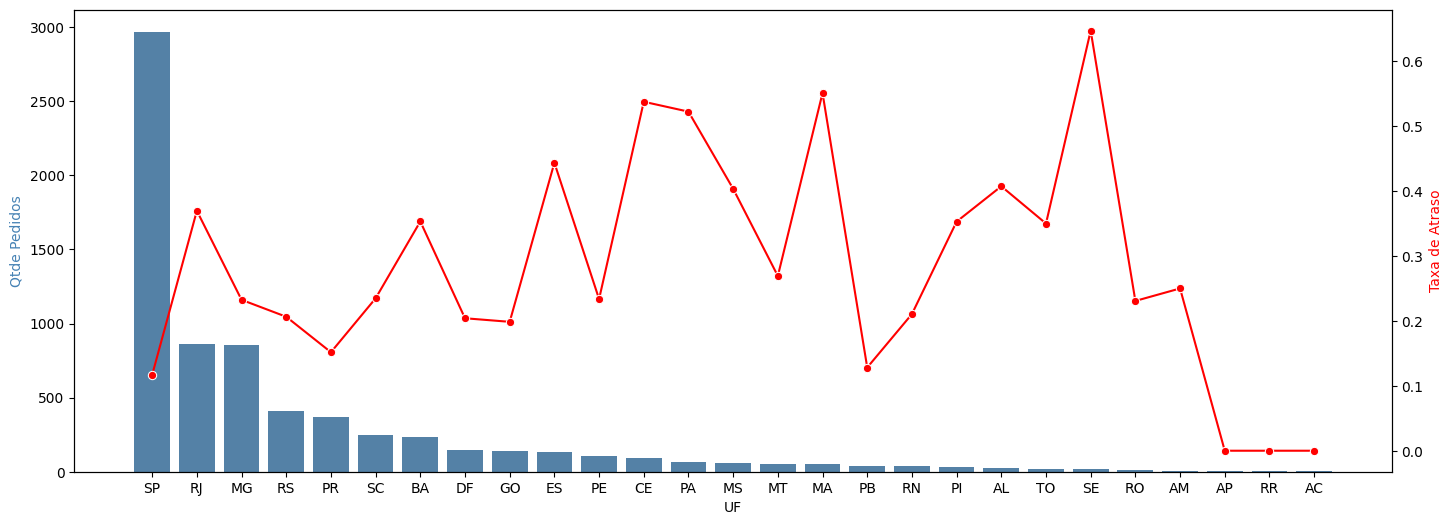

In [36]:
uf_atraso = fato[fato['ano_mes'] == '2018-03'].groupby('customer_state').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()

uf_atraso['taxa_atraso'] = uf_atraso['qtde_atraso'] / uf_atraso['qtde_pedidos']
uf_atraso = uf_atraso.sort_values('qtde_pedidos', ascending=False)

fig, ax1 = plt.subplots(figsize=(17,6))

sns.barplot(data=uf_atraso, x='customer_state', y='qtde_pedidos', ax=ax1, color='steelblue')

ax2 = ax1.twinx()
sns.lineplot(data=uf_atraso, x='customer_state', y='taxa_atraso', ax=ax2, color='red', marker='o')

ax1.set_xlabel('UF')
ax1.set_ylabel('Qtde Pedidos', color='steelblue')
ax2.set_ylabel('Taxa de Atraso', color='red')
plt.xticks(rotation=45)
plt.show()

#### Etapa 5.3 -> Drill down

Verificando atrsos geral por estado

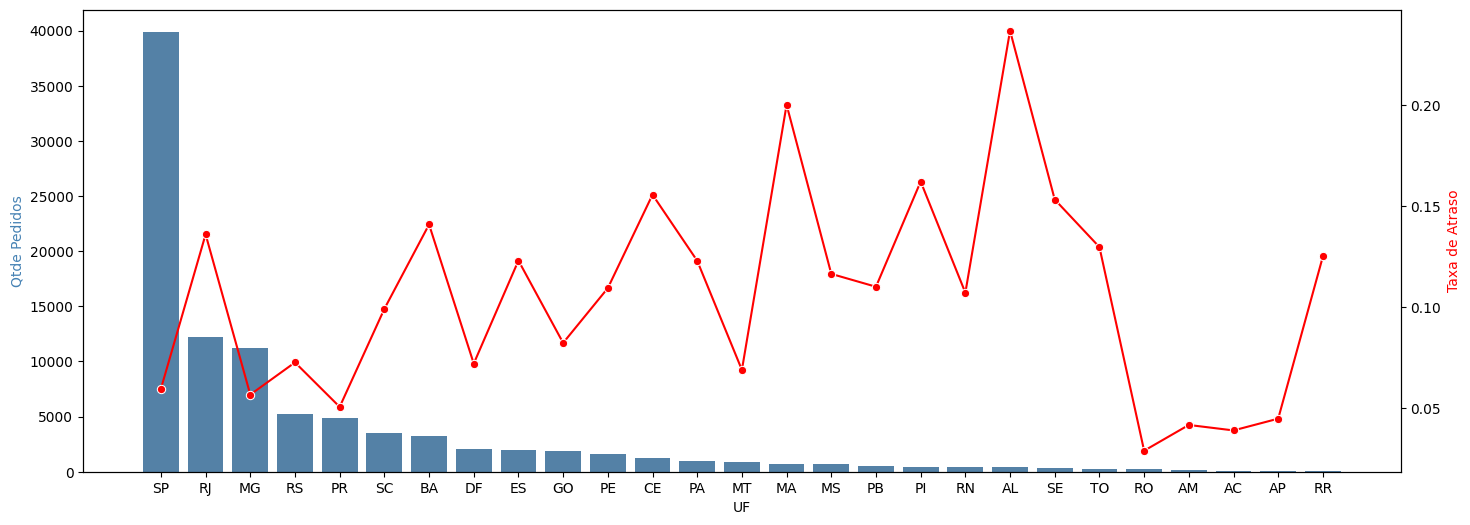

In [37]:
uf_atraso = fato.groupby('customer_state').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()

uf_atraso['taxa_atraso'] = uf_atraso['qtde_atraso'] / uf_atraso['qtde_pedidos']
uf_atraso = uf_atraso.sort_values('qtde_pedidos', ascending=False)

fig, ax1 = plt.subplots(figsize=(17,6))

sns.barplot(data=uf_atraso, x='customer_state', y='qtde_pedidos', ax=ax1, color='steelblue')

ax2 = ax1.twinx()
sns.lineplot(data=uf_atraso, x='customer_state', y='taxa_atraso', ax=ax2, color='red', marker='o')

ax1.set_xlabel('UF')
ax1.set_ylabel('Qtde Pedidos', color='steelblue')
ax2.set_ylabel('Taxa de Atraso', color='red')
plt.xticks(rotation=45)
plt.show()

Verificando por cidade

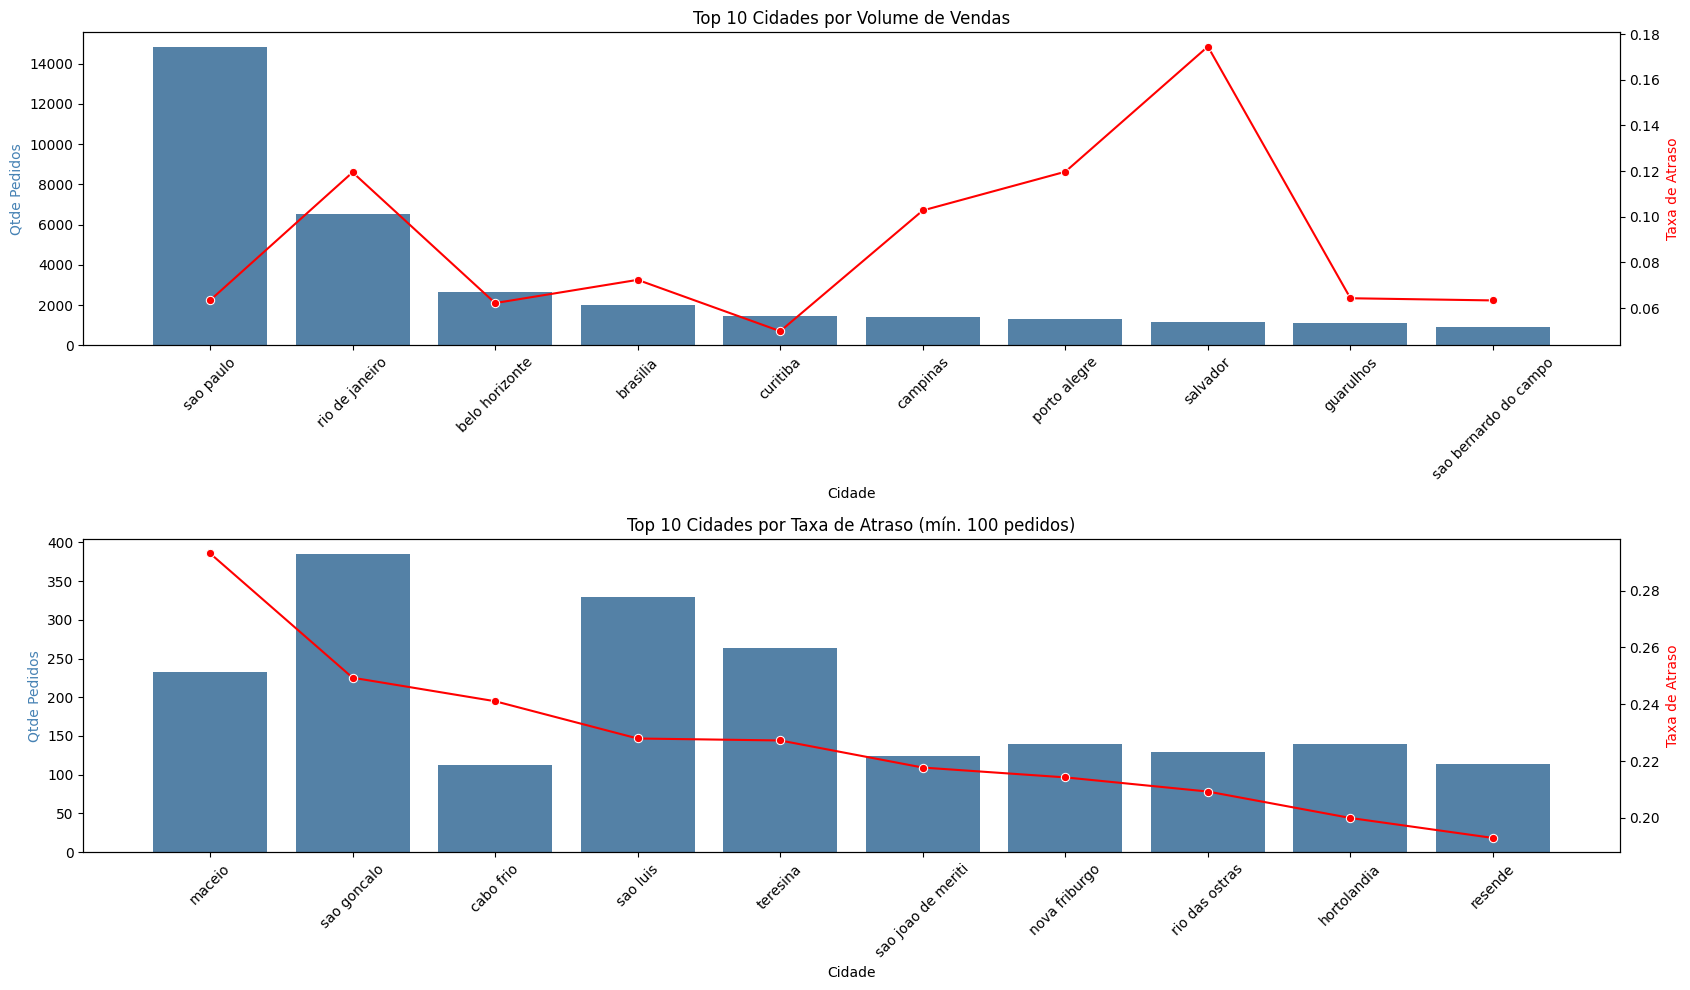

In [38]:
cidade_atraso = fato.groupby('customer_city').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()

cidade_atraso['taxa_atraso'] = cidade_atraso['qtde_atraso'] / cidade_atraso['qtde_pedidos']

# filtra cidades com pelo menos 100 pedidos
cidade_atraso = cidade_atraso[cidade_atraso['qtde_pedidos'] >= 100]

top10_vendas = cidade_atraso.sort_values('qtde_pedidos', ascending=False).head(10)
top10_atraso = cidade_atraso.sort_values('taxa_atraso', ascending=False).head(10)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(17, 10))

sns.barplot(data=top10_vendas, x='customer_city', y='qtde_pedidos', ax=ax1, color='steelblue')
ax1b = ax1.twinx()
sns.lineplot(data=top10_vendas, x='customer_city', y='taxa_atraso', ax=ax1b, color='red', marker='o')
ax1.set_title('Top 10 Cidades por Volume de Vendas')
ax1.set_xlabel('Cidade')
ax1.set_ylabel('Qtde Pedidos', color='steelblue')
ax1b.set_ylabel('Taxa de Atraso', color='red')
ax1.tick_params(axis='x', rotation=45)

sns.barplot(data=top10_atraso, x='customer_city', y='qtde_pedidos', ax=ax2, color='steelblue')
ax2b = ax2.twinx()
sns.lineplot(data=top10_atraso, x='customer_city', y='taxa_atraso', ax=ax2b, color='red', marker='o')
ax2.set_title('Top 10 Cidades por Taxa de Atraso (mín. 100 pedidos)')
ax2.set_xlabel('Cidade')
ax2.set_ylabel('Qtde Pedidos', color='steelblue')
ax2b.set_ylabel('Taxa de Atraso', color='red')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

O padrão é consistente nos dois níveis: as cidades e estados de maior volume (SP, RJ, São Paulo, Rio de Janeiro) têm taxas de atraso relativamente baixas entre 6% e 13%, enquanto as cidades com maior taxa de atraso são todas de médio porte — Maceió, São Gonçalo, São Luís, Teresina — com taxas entre 20% e 30%, revelando que o problema logístico da Olist não está nos grandes centros bem servidos, mas nas capitais e cidades intermediárias do Norte e Nordeste onde a infraestrutura de entrega ainda é deficiente.

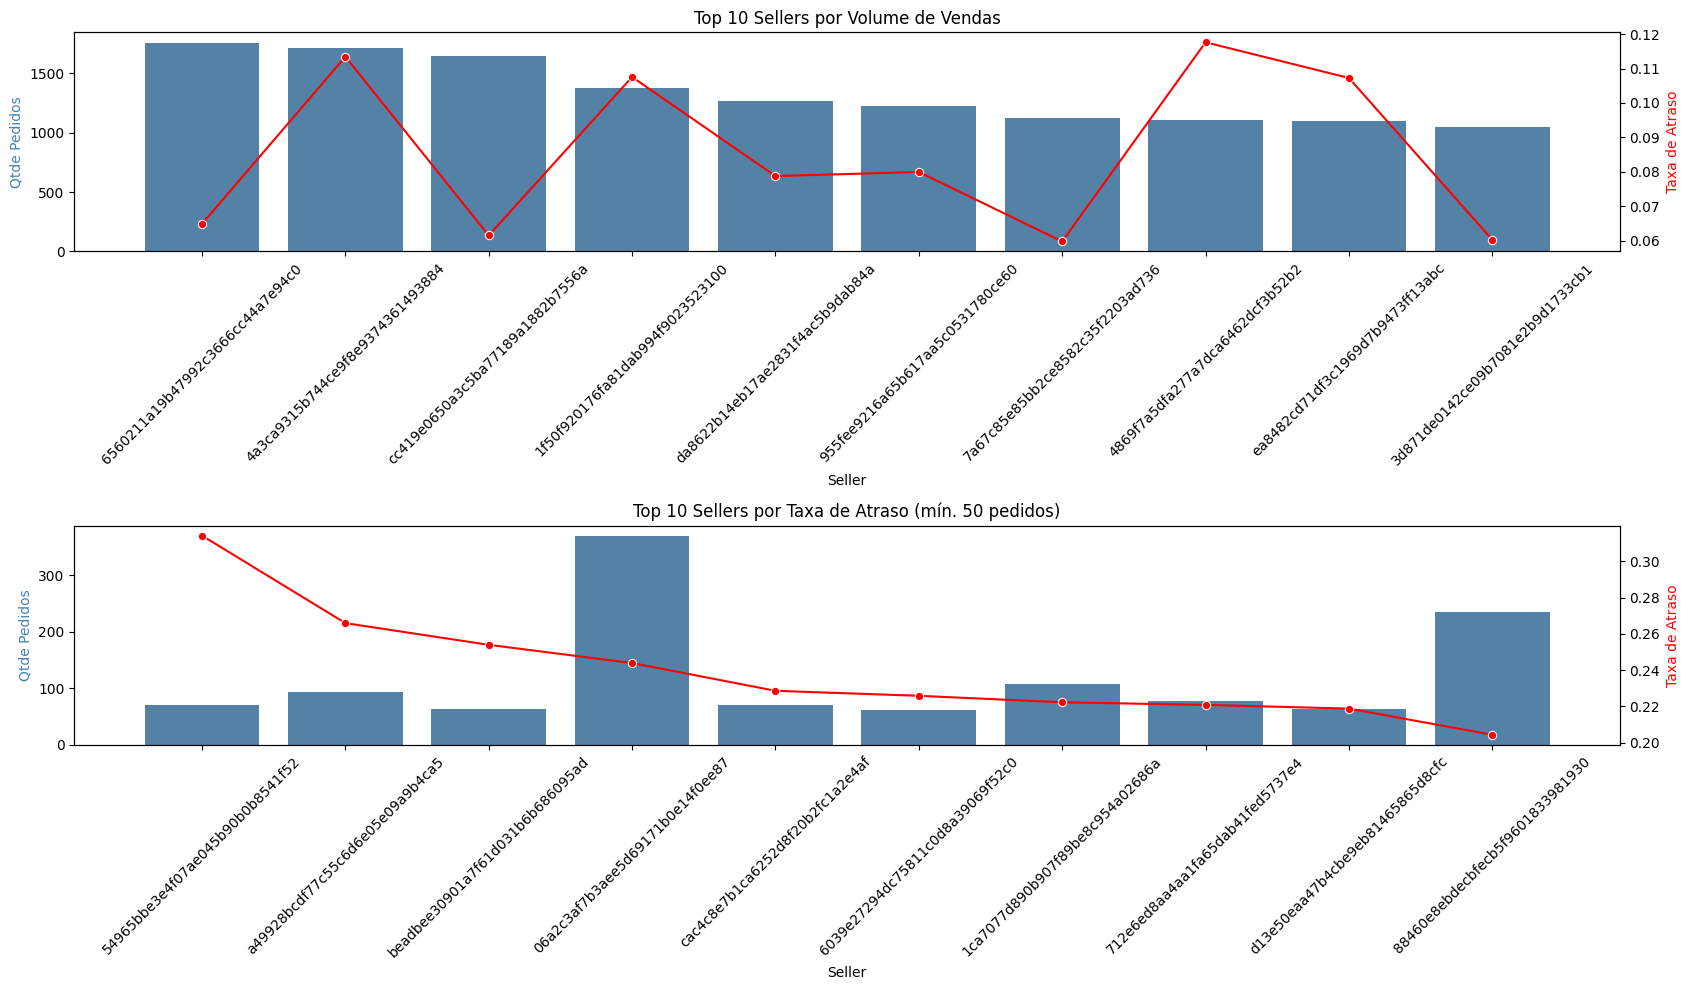

In [39]:
seller_atraso = fato.groupby('seller_id').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()

seller_atraso['taxa_atraso'] = seller_atraso['qtde_atraso'] / seller_atraso['qtde_pedidos']

# filtra sellers com pelo menos 50 pedidos
seller_atraso = seller_atraso[seller_atraso['qtde_pedidos'] >= 50]

top10_vendas = seller_atraso.sort_values('qtde_pedidos', ascending=False).head(10)
top10_atraso = seller_atraso.sort_values('taxa_atraso', ascending=False).head(10)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(17, 10))

sns.barplot(data=top10_vendas, x='seller_id', y='qtde_pedidos', ax=ax1, color='steelblue')
ax1b = ax1.twinx()
sns.lineplot(data=top10_vendas, x='seller_id', y='taxa_atraso', ax=ax1b, color='red', marker='o')
ax1.set_title('Top 10 Sellers por Volume de Vendas')
ax1.set_xlabel('Seller')
ax1.set_ylabel('Qtde Pedidos', color='steelblue')
ax1b.set_ylabel('Taxa de Atraso', color='red')
ax1.tick_params(axis='x', rotation=45)

sns.barplot(data=top10_atraso, x='seller_id', y='qtde_pedidos', ax=ax2, color='steelblue')
ax2b = ax2.twinx()
sns.lineplot(data=top10_atraso, x='seller_id', y='taxa_atraso', ax=ax2b, color='red', marker='o')
ax2.set_title('Top 10 Sellers por Taxa de Atraso (mín. 50 pedidos)')
ax2.set_xlabel('Seller')
ax2.set_ylabel('Qtde Pedidos', color='steelblue')
ax2b.set_ylabel('Taxa de Atraso', color='red')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Os top 10 sellers por volume são relativamente saudáveis, com taxas de atraso entre 6% e 12%, o que indica que os maiores vendedores da plataforma têm operação logística razoavelmente controlada. Já no segundo gráfico, os sellers com maior taxa de atraso chegam a 30% no pior caso e se mantêm entre 20% e 30% ao longo do ranking — todos com volume entre 50 e 350 pedidos — sugerindo que são sellers de médio porte que cresceram sem estrutura suficiente para honrar os prazos, e que merecem atenção ou intervenção da Olist antes de escalarem mais.

### Etapa 5.4 -> Correlação Atraso x Review Score

Vamos arredondar o sla_diff_dias para inteiro, depois criar uma coluna faixa_atraso usando pd.cut que vai categorizar cada pedido em: sem atraso, 1-5 dias, 6-10 dias, 11-20 dias e +20 dias.

In [40]:
fato['sla_diff_dias'] = fato['sla_diff_dias'].round(0)
fato['faixa_atraso'] = pd.cut(
    fato['sla_diff_dias'],
    bins=[-float('inf'), 0, 5, 10, 20, float('inf')],
    labels=['Sem atraso', '1-5 dias', '6-10 dias', '11-20 dias', '+20 dias']
)

fato['faixa_atraso'].value_counts()

faixa_atraso
Sem atraso    87487
1-5 dias       3487
6-10 dias      1864
11-20 dias     1388
+20 dias        871
Name: count, dtype: int64

Criar visualização eentre atraso e review score

<Axes: xlabel='faixa_atraso', ylabel='review_score'>

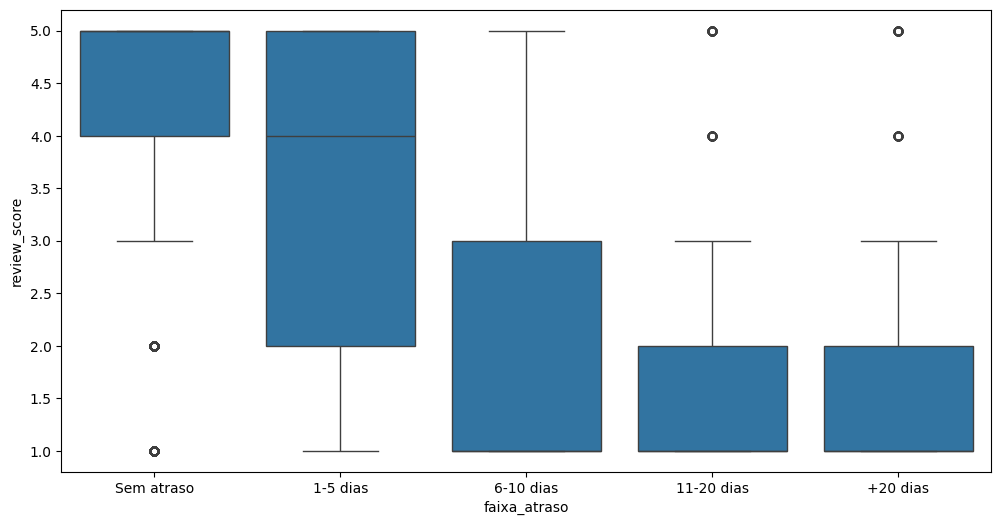

In [44]:
plt.figure(figsize=(12,6))
sns.boxplot(data = fato, x='faixa_atraso',y='review_score')

O gráfico confirma uma relação direta e clara entre atraso e satisfação: pedidos sem atraso têm mediana de nota 5 e distribuição concentrada no topo, enquanto a mediana cai progressivamente para 4 em atrasos leves (1-5 dias), 3 em atrasos moderados (6-10 dias) e despenca para 2 nas faixas mais graves (11-20 dias e +20 dias), demonstrando que a partir de 6 dias de atraso o cliente já está majoritariamente insatisfeito e o impacto na reputação da plataforma é severo.

### Etapa 5.5 -> volume × taxa de atraso. Sellers com volume alto e taxa alta são o maior risco pro negócio.

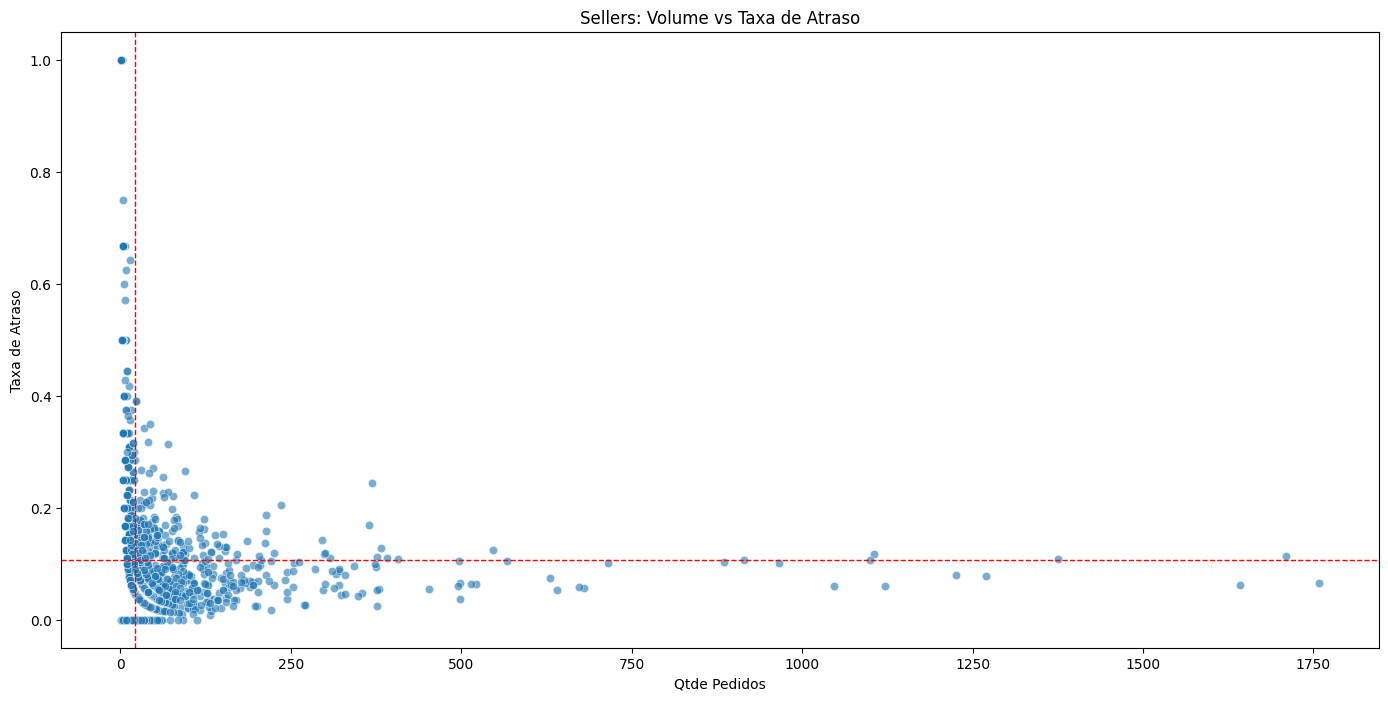

In [45]:
seller_scatter = fato.groupby('seller_id').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()

seller_scatter['taxa_atraso'] = seller_scatter['qtde_atraso'] / seller_scatter['qtde_pedidos']

plt.figure(figsize=(17, 8))
sns.scatterplot(data=seller_scatter, x='qtde_pedidos', y='taxa_atraso', alpha=0.6)

plt.axvline(x=seller_scatter['qtde_pedidos'].quantile(0.75), color='red', linestyle='--', linewidth=1)
plt.axhline(y=seller_scatter['taxa_atraso'].quantile(0.75), color='red', linestyle='--', linewidth=1)

plt.xlabel('Qtde Pedidos')
plt.ylabel('Taxa de Atraso')
plt.title('Sellers: Volume vs Taxa de Atraso')
plt.show()

Sellers de alto volume operam com disciplina logística (abaixo de 15% de atraso), enquanto o risco real está nos sellers de baixo volume — menos de 100 pedidos — onde as taxas chegam a 100% e a falta de estrutura operacional é evidente.

C:\Users\ACER\AppData\Local\Temp\ipykernel_18092\466179201.py:42: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels_dias)


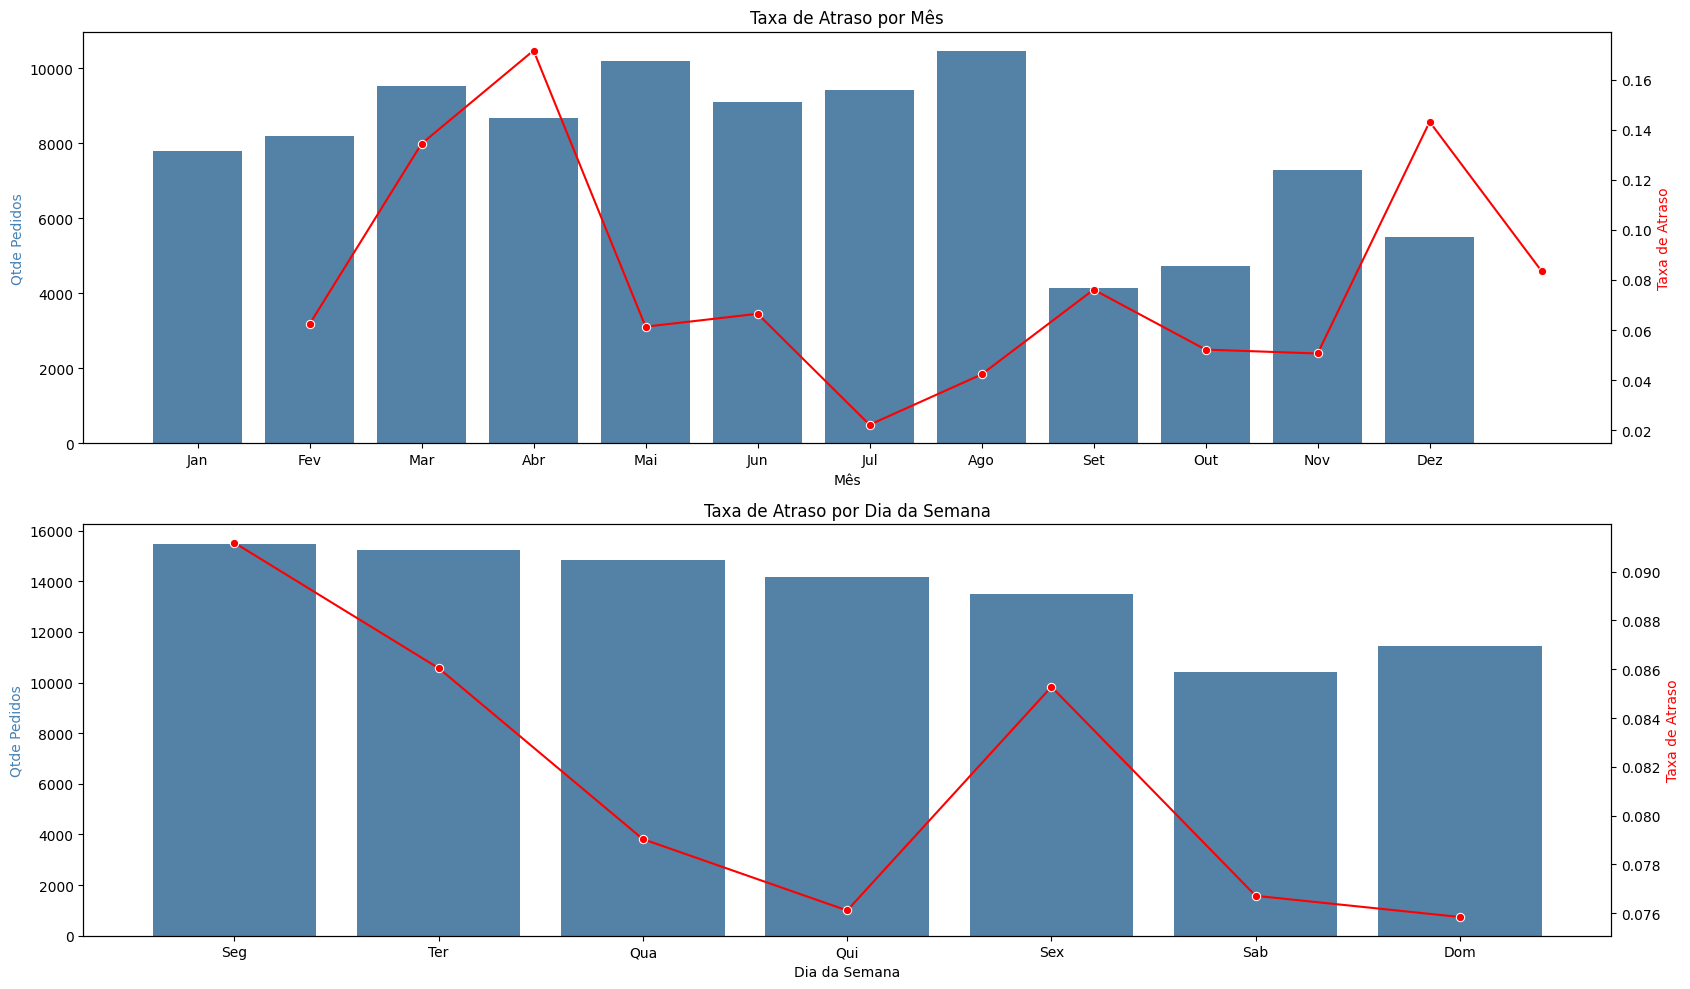

In [46]:
fato['mes'] = fato['order_purchase_timestamp'].dt.month
fato['dia_semana'] = fato['order_purchase_timestamp'].dt.day_name()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(17, 10))

# Gráfico 1 - taxa de atraso por mês
mes_atraso = fato.groupby('mes').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()
mes_atraso['taxa_atraso'] = mes_atraso['qtde_atraso'] / mes_atraso['qtde_pedidos']

sns.barplot(data=mes_atraso, x='mes', y='qtde_pedidos', ax=ax1, color='steelblue')
ax1b = ax1.twinx()
sns.lineplot(data=mes_atraso, x='mes', y='taxa_atraso', ax=ax1b, color='red', marker='o')
ax1.set_title('Taxa de Atraso por Mês')
ax1.set_xlabel('Mês')
ax1.set_ylabel('Qtde Pedidos', color='steelblue')
ax1b.set_ylabel('Taxa de Atraso', color='red')
ax1.set_xticks(range(12))
ax1.set_xticklabels(['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez'])

# Gráfico 2 - taxa de atraso por dia da semana
ordem_dias = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
labels_dias = ['Seg','Ter','Qua','Qui','Sex','Sab','Dom']

dia_atraso = fato.groupby('dia_semana').agg(
    qtde_atraso=('atraso', 'sum'),
    qtde_pedidos=('order_id', 'count')
).reset_index()
dia_atraso['taxa_atraso'] = dia_atraso['qtde_atraso'] / dia_atraso['qtde_pedidos']
dia_atraso['dia_semana'] = pd.Categorical(dia_atraso['dia_semana'], categories=ordem_dias, ordered=True)
dia_atraso = dia_atraso.sort_values('dia_semana')

sns.barplot(data=dia_atraso, x='dia_semana', y='qtde_pedidos', ax=ax2, color='steelblue')
ax2b = ax2.twinx()
sns.lineplot(data=dia_atraso, x='dia_semana', y='taxa_atraso', ax=ax2b, color='red', marker='o')
ax2.set_title('Taxa de Atraso por Dia da Semana')
ax2.set_xlabel('Dia da Semana')
ax2.set_ylabel('Qtde Pedidos', color='steelblue')
ax2b.set_ylabel('Taxa de Atraso', color='red')
ax2.set_xticklabels(labels_dias)

plt.tight_layout()
plt.show()

Os meses de abril (~17%) e dezembro (~14%) concentram os maiores picos de atraso — confirmando o impacto de datas sazonais na logística — enquanto por dia da semana a variação é pequena (entre 7,6% e 9,1%), com segunda-feira tendo a maior taxa, provavelmente por acúmulo de pedidos do fim de semana entrando no sistema sem processamento logístico nos dias anteriores.